# MedTwin AI — Phase 2: Glioma/Tumor Segmentation Training Pipeline

**Project:** MedTwin AI — AI-Based Multi-Disease Brain MRI 3D Reconstruction and Volumetry

**Phase 2 objective:** build and verify a full **3D U-Net (MONAI + PyTorch)** training pipeline for
**glioma/tumor segmentation** on the BraTS 2023 GLI dataset — dataset discovery, quality checks,
preprocessing, model, loss, metrics, a verified forward pass, an optional short training run, test
evaluation, and qualitative visualization.

This notebook:
- Uses **only** the BraTS segmentation labels as provided by the dataset — it never invents label meanings.
- Splits data **at the patient level** so no patient's data leaks across train/validation/test.
- Never uses the segmentation mask as model input — it is the training target only.
- Runs on **CPU by default**, and automatically uses CUDA only if available.
- Does **not** build the web application, the clinical report, or the 15-disease system.
- Is a **research prototype only** — not a clinically validated diagnostic device.

> Run cells in order. Each cell is self-contained and prints what it did. The training loop
> (Cell 18) does **not** run automatically for a long duration — it is deliberately kept short for
> debugging, and must be run explicitly.


## Cell 1 — Environment Verification

Check core packages and detect whether a CUDA GPU is available. The notebook **always** falls back
to CPU automatically — it never requires CUDA.


In [1]:
import sys
import importlib
from importlib.metadata import version as pkg_version, PackageNotFoundError

def check_environment():
    '''Check required packages for the training pipeline and report CUDA availability.
    Never raises if an optional package is missing; reports it instead.'''
    required = ["torch", "torchvision", "monai", "numpy", "nibabel", "SimpleITK", "pandas", "scipy"]

    rows = [("python", sys.version.split()[0], "Available")]
    for name in required:
        try:
            module = importlib.import_module(name)
            try:
                ver = pkg_version(name)
            except PackageNotFoundError:
                ver = getattr(module, "__version__", "unknown")
            rows.append((name, ver, "Available"))
        except ImportError:
            rows.append((name, "-", "Missing"))

    name_w = max(len(r[0]) for r in rows) + 2
    ver_w = max(len(str(r[1])) for r in rows) + 2

    print("Environment Check")
    print("-" * (name_w + ver_w + 12))
    print(f"{'Package':<{name_w}}{'Version':<{ver_w}}{'Status'}")
    print("-" * (name_w + ver_w + 12))
    for name, ver, status in rows:
        print(f"{name:<{name_w}}{str(ver):<{ver_w}}{status}")

    missing = [r[0] for r in rows if r[2] == "Missing"]
    if missing:
        print("\nMissing packages:", ", ".join(missing))
        if "monai" in missing:
            print("Install MONAI with: pip install monai")
        print("Install the rest with: pip install " + " ".join(m for m in missing if m != "monai"))
    else:
        print("\nAll required packages are available.")

    return rows, missing

env_rows, missing_packages = check_environment()


Environment Check
---------------------------------------
Package      Version       Status
---------------------------------------
python       3.11.15       Available
torch        2.11.0+cu128  Available
torchvision  0.26.0+cu128  Available
monai        1.6.0         Available
numpy        2.4.6         Available
nibabel      5.4.2         Available
SimpleITK    2.5.6         Available
pandas       3.0.5         Available
scipy        1.17.1        Available

All required packages are available.


In [2]:
import torch

def select_device():
    '''Select cuda if available, otherwise cpu. Never fails if CUDA is unavailable.'''
    if torch.cuda.is_available():
        device = torch.device("cuda")
        print(f"CUDA available — using GPU: {torch.cuda.get_device_name(0)}")
    else:
        device = torch.device("cpu")
        print("CUDA not available — using CPU. Training will be slower; keep epochs/batch size small.")
    return device

DEVICE = select_device()
print(f"\nSelected device: {DEVICE}")


CUDA available — using GPU: NVIDIA GeForce RTX 5050 Laptop GPU

Selected device: cuda


## Cell 2 — Dataset Discovery

Recursively scan the BraTS dataset directory, find patient folders, and identify each patient's
T1 / T1c / T2 / FLAIR / segmentation files by filename pattern. We do **not** assume every modality
exists for every patient — missing files are recorded, not silently dropped.

Edit `DATASET_DIR` below to match your machine. The path is a Windows path (as given), handled with
`pathlib.Path` so it also works if you move the notebook to another OS.


In [3]:
from pathlib import Path

# ----- EDIT THIS PATH IF NEEDED -----
DATASET_DIR = Path(r"C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData")
OUTPUT_DIR = Path(r"C:\Users\shshi\Downloads\Med_Twin\outputs")
# -------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "checkpoints").mkdir(parents=True, exist_ok=True)

print(f"DATASET_DIR = {DATASET_DIR}")
print(f"OUTPUT_DIR  = {OUTPUT_DIR}")

if not DATASET_DIR.exists():
    print(
        f"\nWARNING: DATASET_DIR does not exist: {DATASET_DIR}\n"
        "Update the path above to point at your local BraTS 2023 GLI training data folder."
    )


DATASET_DIR = C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData
OUTPUT_DIR  = C:\Users\shshi\Downloads\Med_Twin\outputs


In [4]:
import pandas as pd

# ----- Single source of truth for modality naming, used everywhere in this notebook -----
# MODALITY_KEYS are the canonical internal names used for dataframe columns, MONAI data dicts,
# and transform keys. MODALITY_FILENAME_SUFFIXES maps each canonical key to the actual BraTS
# 2023 GLI filename suffix on disk. Changing either dict here automatically propagates to every
# later cell — no key names are ever hardcoded a second time elsewhere in the notebook.
MODALITY_KEYS = ["t1", "t1c", "t2", "flair"]
LABEL_KEY = "seg"

MODALITY_FILENAME_SUFFIXES = {
    "t1": "-t1n.nii.gz",
    "t1c": "-t1c.nii.gz",
    "t2": "-t2w.nii.gz",
    "flair": "-t2f.nii.gz",
}
LABEL_FILENAME_SUFFIX = "-seg.nii.gz"
# -------------------------------------------------------------------------------------------

def _path_column(key: str) -> str:
    '''Dataframe column name for a given canonical modality/label key, e.g. "t1" -> "t1_path".'''
    return f"{key}_path"

def discover_patients(dataset_dir: Path) -> pd.DataFrame:
    '''Recursively find patient folders and match each expected modality file by suffix.
    Does not assume every file exists; missing files are recorded as None.
    Dataframe columns are named from MODALITY_KEYS/LABEL_KEY, so they always match the keys
    used later when building MONAI data dicts.'''
    all_suffixes = dict(MODALITY_FILENAME_SUFFIXES)
    all_suffixes[LABEL_KEY] = LABEL_FILENAME_SUFFIX
    path_columns = [_path_column(k) for k in all_suffixes]

    if not dataset_dir.exists():
        print(f"Dataset directory not found: {dataset_dir}")
        return pd.DataFrame(columns=["patient_id"] + path_columns + ["complete_case"])

    # A "patient folder" is any directory directly containing at least one BraTS-style file.
    candidate_dirs = sorted({p.parent for p in dataset_dir.rglob("*.nii.gz")})

    records = []
    for pdir in candidate_dirs:
        patient_id = pdir.name
        record = {"patient_id": patient_id}
        for key, suffix in all_suffixes.items():
            matches = list(pdir.glob(f"*{suffix}"))
            record[_path_column(key)] = str(matches[0]) if matches else None
        record["complete_case"] = all(record[_path_column(k)] is not None for k in all_suffixes)
        records.append(record)

    df = pd.DataFrame(records)
    if not df.empty:
        df = df.sort_values("patient_id").reset_index(drop=True)
    return df

patients_df = discover_patients(DATASET_DIR)
print(f"Discovered {len(patients_df)} patient folder(s).")
patients_df.head(10)


Discovered 1251 patient folder(s).


,patient_id,t1_path,t1c_path,t2_path,flair_path,seg_path,complete_case
0,BraTS-GLI-00000-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
1,BraTS-GLI-00002-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
2,BraTS-GLI-00003-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
3,BraTS-GLI-00005-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
4,BraTS-GLI-00006-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
5,BraTS-GLI-00008-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
6,BraTS-GLI-00008-001,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
7,BraTS-GLI-00009-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
8,BraTS-GLI-00009-001,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True
9,BraTS-GLI-00011-000,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR...,True


## Cell 3 — Dataset Quality Report

Summarize completeness across the discovered patients. Incomplete cases are **not** removed here —
they are reported so you can decide how to handle them explicitly.


In [5]:
def dataset_quality_report(df: pd.DataFrame):
    total = len(df)
    complete = int(df["complete_case"].sum()) if total else 0

    # Driven by the same MODALITY_KEYS / LABEL_KEY defined in Cell 2 — no column names repeated here.
    report_keys = MODALITY_KEYS + [LABEL_KEY]
    missing_counts = {}
    for key in report_keys:
        col = _path_column(key)
        missing_counts[key] = int(df[col].isna().sum()) if total else 0

    print("Dataset Quality Report")
    print("-" * 40)
    print(f"Total patients:          {total}")
    print(f"Complete patients:       {complete}")
    print(f"Incomplete patients:     {total - complete}")
    for key in report_keys:
        label = "segmentation" if key == LABEL_KEY else key.upper()
        print(f"Missing {label:<21}: {missing_counts[key]}")

    if total - complete > 0:
        print("\nIncomplete patients (kept in the table, excluded from training later):")
        incomplete_ids = df.loc[~df["complete_case"], "patient_id"].tolist()
        for pid in incomplete_ids:
            print(f"  - {pid}")

    return missing_counts

quality_report = dataset_quality_report(patients_df)


Dataset Quality Report
----------------------------------------
Total patients:          1251
Complete patients:       1251
Incomplete patients:     0
Missing T1                   : 0
Missing T1C                  : 0
Missing T2                   : 0
Missing FLAIR                : 0
Missing segmentation         : 0


## Cell 4 — Verify MRI and Mask Compatibility

For a sample of complete patients, load each modality and the mask with NiBabel and check that
shapes, voxel spacing, affine, and orientation are consistent. Incompatible cases are reported, not
silently fixed or dropped.


In [6]:
import nibabel as nib
import numpy as np

def check_patient_compatibility(row, rtol=1e-3):
    '''Load all modalities + mask for one patient and check shape/spacing/affine/orientation match.'''
    issues = []
    shapes = {}
    spacings = {}
    axcodes = {}

    for key in MODALITY_KEYS + [LABEL_KEY]:
        col = _path_column(key)
        path = row[col]
        if path is None:
            issues.append(f"{col} missing — skipped")
            continue
        img = nib.load(path)
        shapes[col] = img.shape
        affine = img.affine
        spacing = tuple(np.round(np.sqrt(np.sum(affine[:3, :3] ** 2, axis=0)), 4))
        spacings[col] = spacing
        axcodes[col] = nib.orientations.aff2axcodes(affine)

    if shapes:
        ref_shape = next(iter(shapes.values()))
        for col, shape in shapes.items():
            if shape != ref_shape:
                issues.append(f"Shape mismatch: {col}={shape} vs reference={ref_shape}")

    if spacings:
        ref_spacing = next(iter(spacings.values()))
        for col, spacing in spacings.items():
            if not np.allclose(spacing, ref_spacing, rtol=rtol):
                issues.append(f"Spacing mismatch: {col}={spacing} vs reference={ref_spacing}")

    if axcodes:
        ref_ax = next(iter(axcodes.values()))
        for col, ax in axcodes.items():
            if ax != ref_ax:
                issues.append(f"Orientation mismatch: {col}={ax} vs reference={ref_ax}")

    return {
        "patient_id": row["patient_id"],
        "shapes": shapes,
        "spacings": spacings,
        "orientations": axcodes,
        "compatible": len(issues) == 0,
        "issues": issues,
    }

N_CHECK = min(5, int(patients_df["complete_case"].sum())) if len(patients_df) else 0
sample_complete = patients_df[patients_df["complete_case"]].head(N_CHECK)

compatibility_results = []
for _, row in sample_complete.iterrows():
    result = check_patient_compatibility(row)
    compatibility_results.append(result)

    status = "COMPATIBLE" if result["compatible"] else "INCOMPATIBLE"
    print(f"{result['patient_id']}: {status}")
    if result["shapes"]:
        example_shape = next(iter(result["shapes"].values()))
        example_spacing = next(iter(result["spacings"].values()))
        print(f"    shape={example_shape}  spacing={example_spacing}")
    for issue in result["issues"]:
        print(f"    ISSUE: {issue}")

if not compatibility_results:
    print("No complete patients available to check yet.")

incompatible = [r for r in compatibility_results if not r["compatible"]]
print(f"\nChecked {len(compatibility_results)} patient(s); {len(incompatible)} incompatible.")


BraTS-GLI-00000-000: COMPATIBLE
    shape=(240, 240, 155)  spacing=(np.float64(1.0), np.float64(1.0), np.float64(1.0))
BraTS-GLI-00002-000: COMPATIBLE
    shape=(240, 240, 155)  spacing=(np.float64(1.0), np.float64(1.0), np.float64(1.0))
BraTS-GLI-00003-000: COMPATIBLE
    shape=(240, 240, 155)  spacing=(np.float64(1.0), np.float64(1.0), np.float64(1.0))
BraTS-GLI-00005-000: COMPATIBLE
    shape=(240, 240, 155)  spacing=(np.float64(1.0), np.float64(1.0), np.float64(1.0))
BraTS-GLI-00006-000: COMPATIBLE
    shape=(240, 240, 155)  spacing=(np.float64(1.0), np.float64(1.0), np.float64(1.0))

Checked 5 patient(s); 0 incompatible.


## Cell 5 — Visualize Training Examples

Randomly select a few complete, compatible patients and display FLAIR, T1c, T2, and the
segmentation overlay, using axial, coronal, and sagittal views where practical.


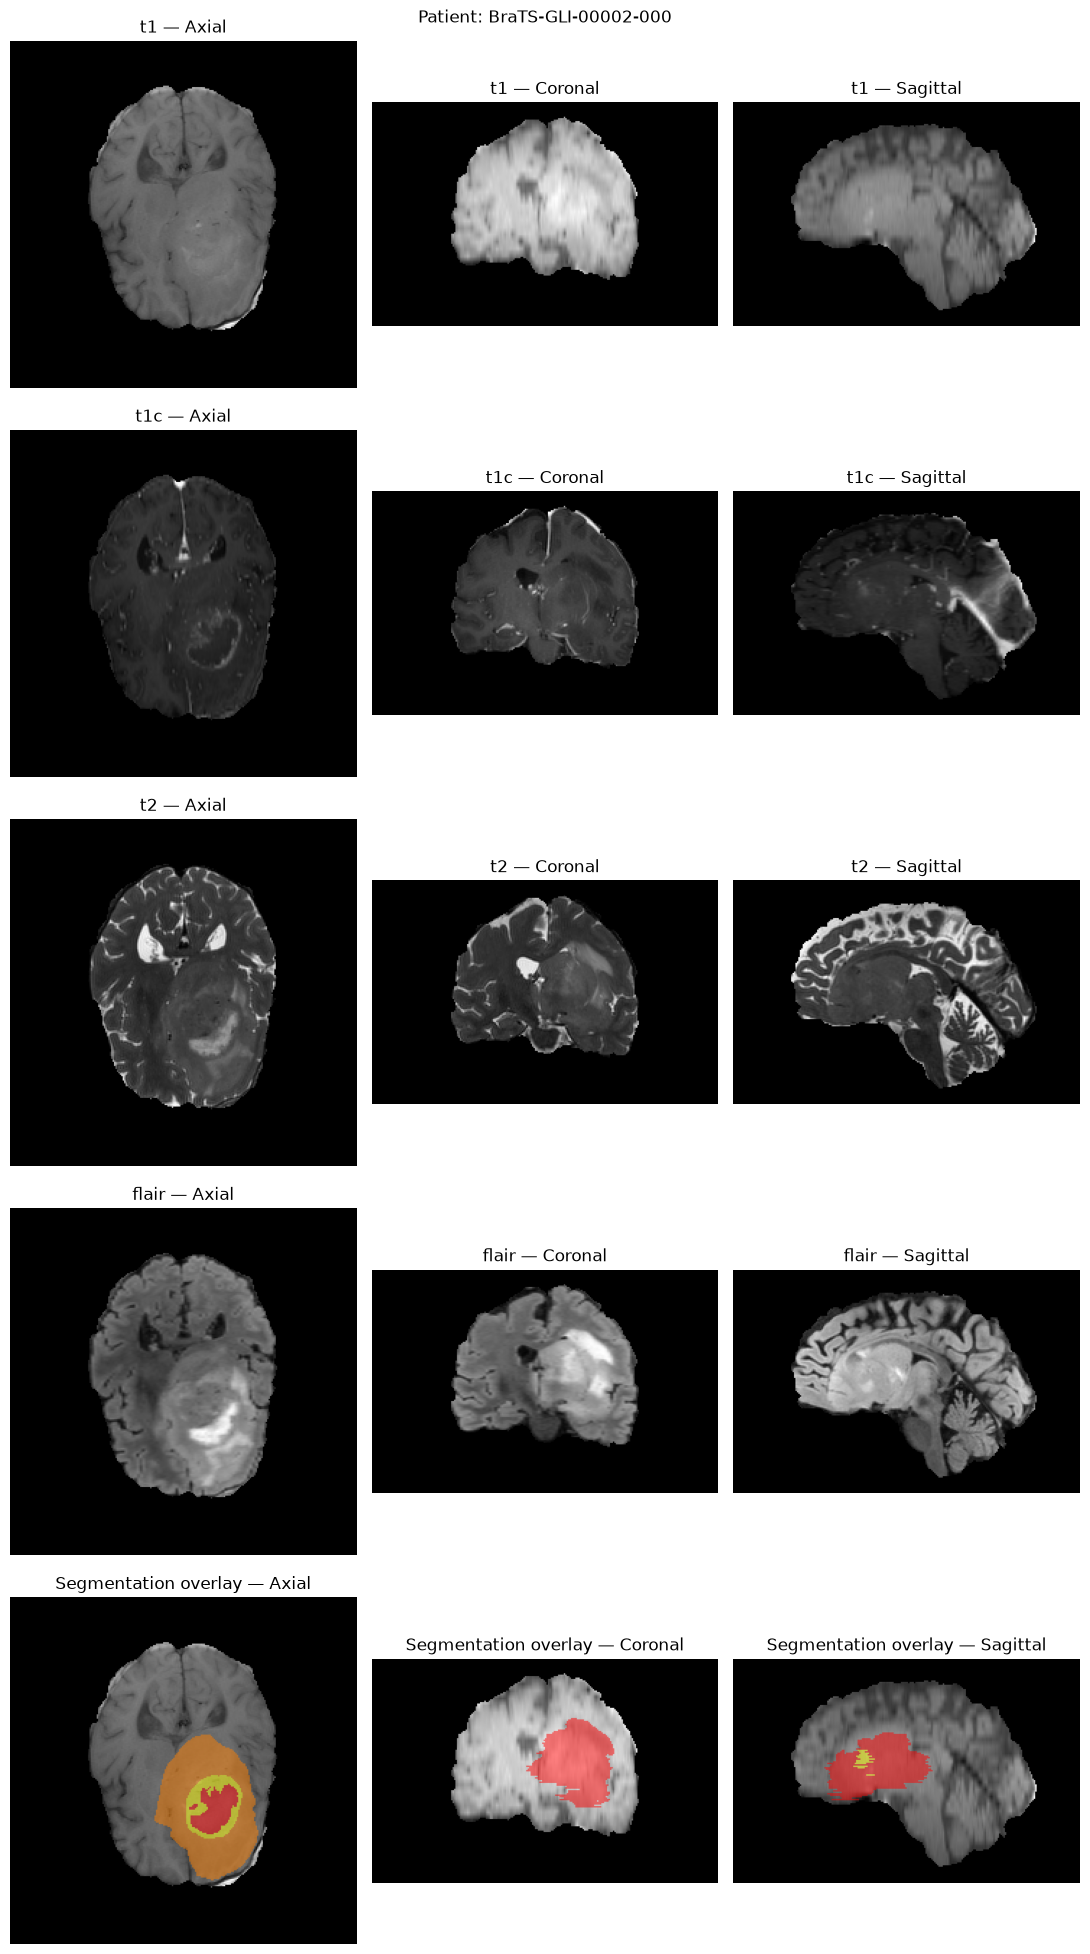

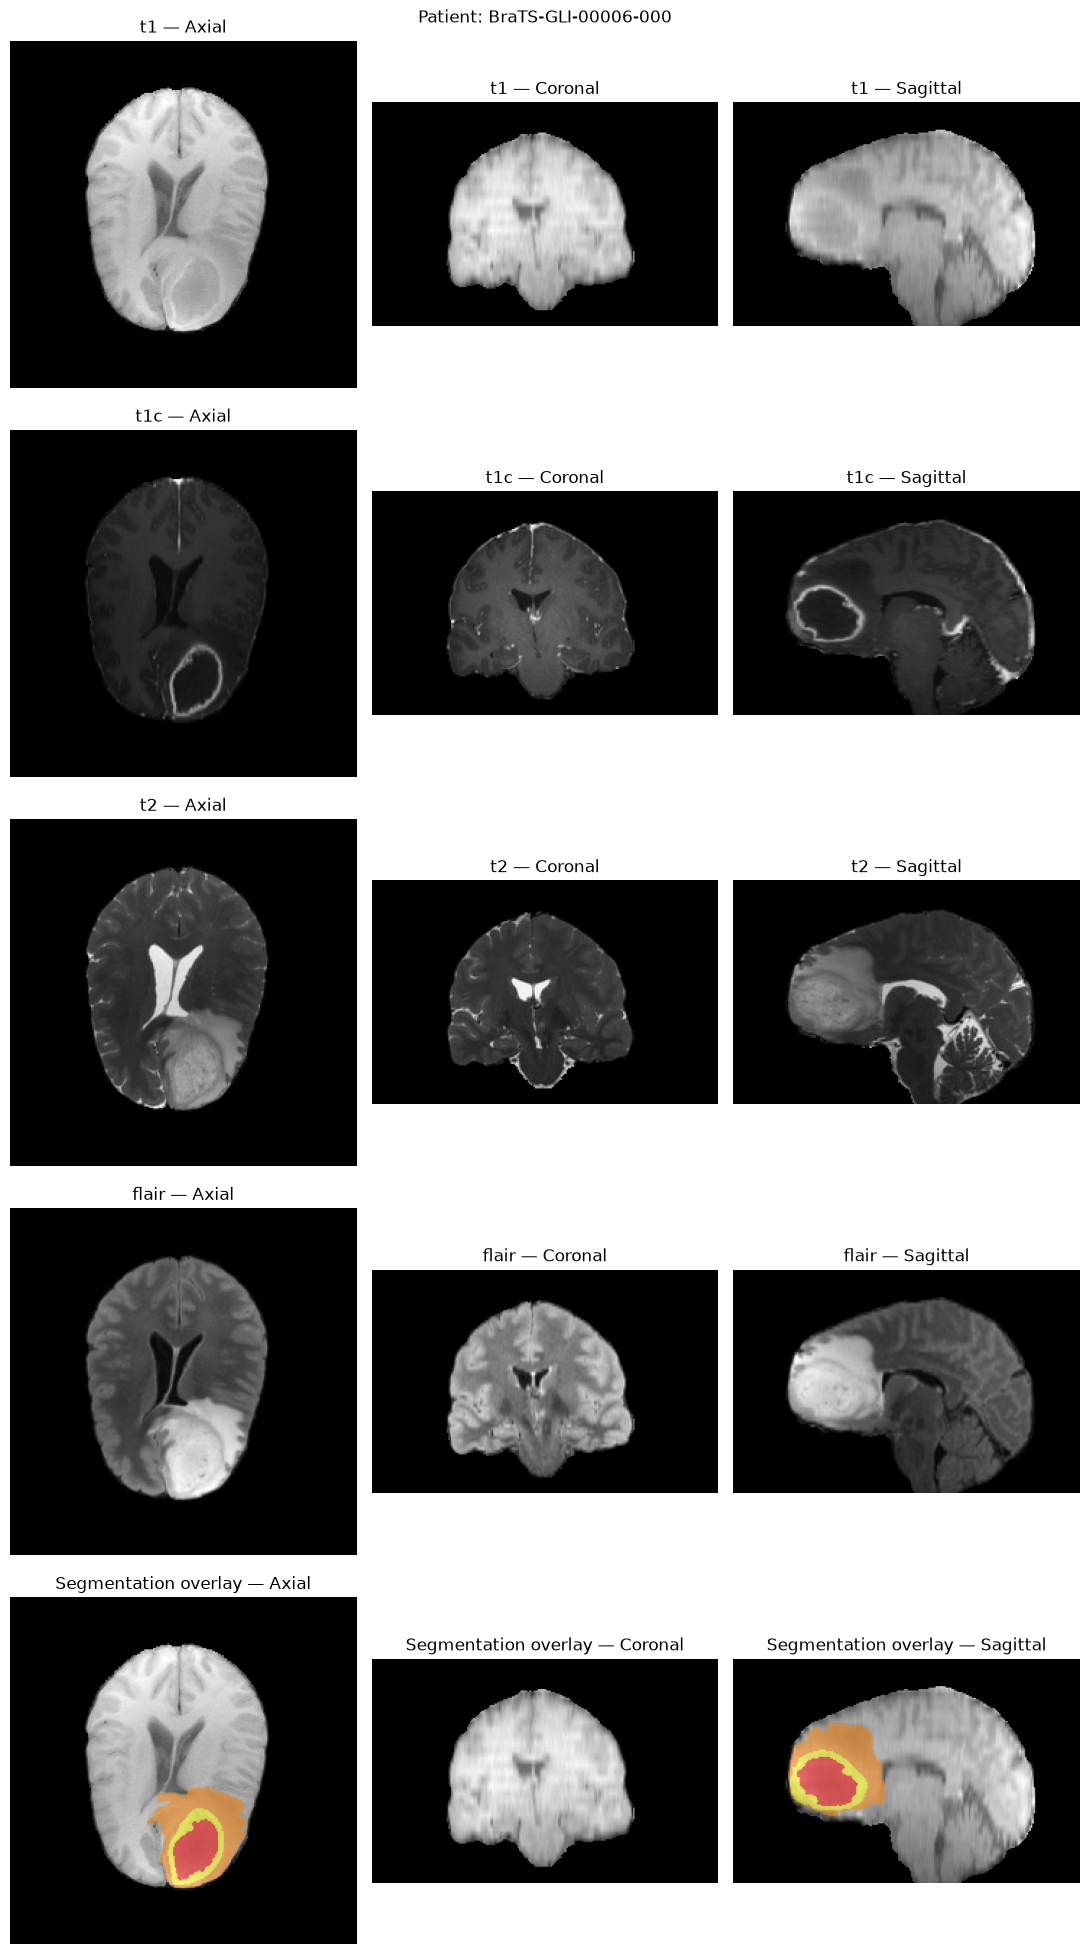

In [7]:
import matplotlib.pyplot as plt
import random

RANDOM_SEED = 42
random.seed(RANDOM_SEED)

def get_mid_slices(volume):
    '''Return (axial, coronal, sagittal) middle slices for a 3D array, assuming array axes
    already correspond to (x, y, z) as loaded (no reorientation applied here; this is a quick look).'''
    x, y, z = volume.shape
    axial = volume[:, :, z // 2]
    coronal = volume[:, y // 2, :]
    sagittal = volume[x // 2, :, :]
    return axial, coronal, sagittal

def visualize_patient_example(row):
    '''Display every modality in MODALITY_KEYS plus a segmentation overlay, using whatever
    modality keys are currently configured (no semantic names hardcoded).'''
    volumes = {key: nib.load(row[_path_column(key)]).get_fdata() for key in MODALITY_KEYS}
    seg = nib.load(row[_path_column(LABEL_KEY)]).get_fdata()

    n_rows = len(volumes) + 1
    fig, axes = plt.subplots(n_rows, 3, figsize=(11, 4 * n_rows))

    for r, (name, vol) in enumerate(volumes.items()):
        axial, coronal, sagittal = get_mid_slices(vol)
        for c, (plane_name, sl) in enumerate(zip(["Axial", "Coronal", "Sagittal"],
                                                    [axial, coronal, sagittal])):
            axes[r, c].imshow(sl.T, cmap="gray", origin="lower")
            axes[r, c].set_title(f"{name} — {plane_name}")
            axes[r, c].axis("off")

    # Overlay the segmentation on the first configured modality (order-independent choice).
    base_vol = next(iter(volumes.values()))
    seg_axial, seg_coronal, seg_sagittal = get_mid_slices(seg)
    base_axial, base_coronal, base_sagittal = get_mid_slices(base_vol)
    for c, (plane_name, base, overlay) in enumerate(zip(
            ["Axial", "Coronal", "Sagittal"],
            [base_axial, base_coronal, base_sagittal],
            [seg_axial, seg_coronal, seg_sagittal])):
        axes[-1, c].imshow(base.T, cmap="gray", origin="lower")
        masked = np.ma.masked_where(overlay.T == 0, overlay.T)
        axes[-1, c].imshow(masked, cmap="autumn", alpha=0.5, origin="lower")
        axes[-1, c].set_title(f"Segmentation overlay — {plane_name}")
        axes[-1, c].axis("off")

    fig.suptitle(f"Patient: {row['patient_id']}")
    plt.tight_layout()
    plt.show()

compatible_ids = {r["patient_id"] for r in compatibility_results if r["compatible"]}
viz_candidates = patients_df[patients_df["patient_id"].isin(compatible_ids)]

N_VIZ = min(2, len(viz_candidates))
if N_VIZ > 0:
    viz_sample = viz_candidates.sample(n=N_VIZ, random_state=RANDOM_SEED)
    for _, row in viz_sample.iterrows():
        visualize_patient_example(row)
else:
    print("No compatible complete patients available to visualize yet.")


## Cell 6 — Define Preprocessing (MONAI transforms)

A configurable MONAI preprocessing pipeline for 3D multimodal brain MRI segmentation:
`LoadImaged → EnsureChannelFirstd → Orientationd → Spacingd → NormalizeIntensityd → CropForegroundd`.

Target spacing and orientation are configurable constants. Intensity normalization is applied to the
**images only** — segmentation labels are preserved with nearest-neighbor interpolation so label
values are never blended or destroyed.


In [8]:
from monai.transforms import (
    Compose, LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd,
    NormalizeIntensityd, CropForegroundd, ConcatItemsd, DeleteItemsd, EnsureTyped,
    DivisiblePadd
)

# ----- Configurable preprocessing settings -----
# NOTE: MODALITY_KEYS / LABEL_KEY are already defined in Cell 2 (single source of truth used by
# dataset discovery, the data-dict builder in Cell 9, and here) — not redefined in this cell.
TARGET_ORIENTATION = "RAS"
TARGET_SPACING = (1.0, 1.0, 1.0)  # mm; matches native BraTS spacing, kept explicit and configurable

# The 3D U-Net below (Cell 13) downsamples with these strides; CropForegroundd can produce a
# bounding box whose size is not divisible by the total downsampling factor, which breaks the
# decoder's skip connections. DivisiblePadd (added below) pads up to the nearest multiple so the
# model's encoder/decoder shapes always line up, whatever the crop size turns out to be.
UNET_STRIDES = (2, 2, 2)
DOWNSAMPLE_FACTOR = 1
for _s in UNET_STRIDES:
    DOWNSAMPLE_FACTOR *= _s
# -------------------------------------------------

def build_preprocessing_transforms(orientation=TARGET_ORIENTATION, spacing=TARGET_SPACING):
    '''Build the MONAI preprocessing Compose pipeline. Images are normalized; the label is not.'''
    all_keys = MODALITY_KEYS + [LABEL_KEY]

    transforms = Compose([
        LoadImaged(keys=all_keys, image_only=True),
        EnsureChannelFirstd(keys=all_keys),
        Orientationd(keys=all_keys, axcodes=orientation),
        Spacingd(
            keys=all_keys,
            pixdim=spacing,
            mode=["bilinear"] * len(MODALITY_KEYS) + ["nearest"],  # nearest for label: no blended labels
        ),
        NormalizeIntensityd(keys=MODALITY_KEYS, nonzero=True, channel_wise=True),
        ConcatItemsd(keys=MODALITY_KEYS, name="image"),
        DeleteItemsd(keys=MODALITY_KEYS),
        CropForegroundd(keys=["image", LABEL_KEY], source_key="image"),
        # Pad up to a multiple of the U-Net's total downsampling factor so encoder/decoder
        # feature maps always match size on the way back up, regardless of crop size.
        DivisiblePadd(keys=["image", LABEL_KEY], k=DOWNSAMPLE_FACTOR),
        EnsureTyped(keys=["image", LABEL_KEY]),
    ])
    return transforms

preprocessing_transforms = build_preprocessing_transforms()
print("Preprocessing pipeline created:")
for t in preprocessing_transforms.transforms:
    print(f"  - {type(t).__name__}")


Preprocessing pipeline created:
  - LoadImaged
  - EnsureChannelFirstd
  - Orientationd
  - Spacingd
  - NormalizeIntensityd
  - ConcatItemsd
  - DeleteItemsd
  - CropForegroundd
  - DivisiblePadd
  - EnsureTyped


C:\Users\shshi\anaconda3\envs\Med_twin\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


## Cell 7 — Define Training Labels

BraTS 2023 GLI segmentation masks use these label values (per the official BraTS annotation
protocol):

| Label | Meaning |
|------:|---------|
| 0 | Background (no tumor) |
| 1 | Necrotic tumor core (NCR) |
| 2 | Peritumoral edematous/invaded tissue (ED) |
| 3 | Enhancing tumor (ET) |

*(BraTS 2023 renumbered the historically-used label 4 "enhancing tumor" to label 3; verify this
against the dataset's own documentation/readme for the exact BraTS-GLI 2023 release you downloaded,
since label numbering has changed between BraTS years.)*

We keep the **original label values** for training (no merging) so the model directly predicts the
dataset's own classes. If you later want composite regions (e.g. "whole tumor" = labels 1+2+3, or
"tumor core" = labels 1+3, as commonly reported in BraTS challenge metrics), that mapping is defined
explicitly below and used **only for reporting**, not for training targets.


In [9]:
# Original BraTS label values used as the actual training targets — not altered.
RAW_LABELS = {0: "background", 1: "necrotic_core", 2: "edema", 3: "enhancing_tumor"}
NUM_CLASSES = len(RAW_LABELS)

# Optional composite regions, used ONLY for reporting metrics in later cells — documented explicitly,
# never substituted as the training target.
COMPOSITE_REGION_MAPPING = {
    "whole_tumor": [1, 2, 3],
    "tumor_core": [1, 3],
    "enhancing_tumor": [3],
}

print("Training label convention (unmodified from dataset):")
for label, name in RAW_LABELS.items():
    print(f"  {label}: {name}")

print(f"\nNumber of classes (including background): {NUM_CLASSES}")

print("\nComposite region mapping (reporting only, NOT used as training target):")
for region, labels in COMPOSITE_REGION_MAPPING.items():
    print(f"  {region}: labels {labels}")


Training label convention (unmodified from dataset):
  0: background
  1: necrotic_core
  2: edema
  3: enhancing_tumor

Number of classes (including background): 4

Composite region mapping (reporting only, NOT used as training target):
  whole_tumor: labels [1, 2, 3]
  tumor_core: labels [1, 3]
  enhancing_tumor: labels [3]


## Cell 8 — Create Patient-Level Split

Split **patients** (not slices, not volumes-within-patient) into train/validation/test so no
patient's data can appear in more than one split. Fixed random seed for reproducibility.


In [10]:
from sklearn.model_selection import train_test_split

SPLIT_SEED = 42
TRAIN_FRACTION = 0.70
VAL_FRACTION = 0.15
TEST_FRACTION = 0.15

def split_patients(df: pd.DataFrame, train_frac=TRAIN_FRACTION, val_frac=VAL_FRACTION, seed=SPLIT_SEED):
    '''Patient-level split. Only complete_case patients are eligible for training.'''
    eligible = df[df["complete_case"]].reset_index(drop=True)
    if len(eligible) == 0:
        print("No complete patients available — cannot create a split yet.")
        return eligible, eligible, eligible

    train_ids, temp_ids = train_test_split(eligible, train_size=train_frac, random_state=seed)
    relative_val_frac = val_frac / (val_frac + TEST_FRACTION)
    val_ids, test_ids = train_test_split(temp_ids, train_size=relative_val_frac, random_state=seed)

    # Sanity check: no patient_id overlap between splits.
    assert set(train_ids["patient_id"]).isdisjoint(set(val_ids["patient_id"]))
    assert set(train_ids["patient_id"]).isdisjoint(set(test_ids["patient_id"]))
    assert set(val_ids["patient_id"]).isdisjoint(set(test_ids["patient_id"]))

    return train_ids.reset_index(drop=True), val_ids.reset_index(drop=True), test_ids.reset_index(drop=True)

train_df, val_df, test_df = split_patients(patients_df)

print("Patient-level split (no overlap by construction)")
print("-" * 40)
print(f"Training patients:   {len(train_df)}")
print(f"Validation patients: {len(val_df)}")
print(f"Test patients:       {len(test_df)}")


Patient-level split (no overlap by construction)
----------------------------------------
Training patients:   875
Validation patients: 188
Test patients:       188


## Cell 9 — Create MONAI Datasets

Build `train_ds` / `val_ds` / `test_ds`. Because this machine is CPU-based with potentially limited
RAM, we use a plain `monai.data.Dataset` (loads lazily per-sample) rather than caching the entire
dataset in memory. If you have enough RAM, you can later switch to `CacheDataset` for speed.


In [11]:
from monai.data import Dataset

def df_to_data_dicts(df: pd.DataFrame):
    '''Convert a patients dataframe into MONAI-style list-of-dicts input.
    Keys are driven by MODALITY_KEYS / LABEL_KEY (defined once in Cell 2) so they always match
    the keys the preprocessing transforms (Cell 6) expect — even if MODALITY_KEYS is customized.'''
    records = []
    for _, row in df.iterrows():
        record = {key: row[_path_column(key)] for key in MODALITY_KEYS}
        record[LABEL_KEY] = row[_path_column(LABEL_KEY)]
        record["patient_id"] = row["patient_id"]
        records.append(record)
    return records

train_data = df_to_data_dicts(train_df)
val_data = df_to_data_dicts(val_df)
test_data = df_to_data_dicts(test_df)

# Plain Dataset: no upfront caching, keeps CPU memory usage low.
train_ds = Dataset(data=train_data, transform=preprocessing_transforms)
val_ds = Dataset(data=val_data, transform=preprocessing_transforms)
test_ds = Dataset(data=test_data, transform=preprocessing_transforms)

print(f"train_ds: {len(train_ds)} samples")
print(f"val_ds:   {len(val_ds)} samples")
print(f"test_ds:  {len(test_ds)} samples")


train_ds: 875 samples
val_ds:   188 samples
test_ds:  188 samples


## Cell 10 — Create DataLoaders

Conservative settings for CPU/Windows: `batch_size=1`, `num_workers=0`.


In [12]:
from monai.data import DataLoader

BATCH_SIZE = 1
NUM_WORKERS = 0  # 0 for Windows compatibility; increase cautiously on Linux/Mac if RAM allows

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

print(f"train_loader: batch_size={BATCH_SIZE}, num_workers={NUM_WORKERS}, batches={len(train_loader)}")
print(f"val_loader:   batch_size={BATCH_SIZE}, num_workers={NUM_WORKERS}, batches={len(val_loader)}")
print(f"test_loader:  batch_size={BATCH_SIZE}, num_workers={NUM_WORKERS}, batches={len(test_loader)}")


train_loader: batch_size=1, num_workers=0, batches=875
val_loader:   batch_size=1, num_workers=0, batches=188
test_loader:  batch_size=1, num_workers=0, batches=188


## Cell 11 — Inspect One Batch

Load a single batch and print its shape/dtype/value range. Image tensor should be
`(batch, modalities, X, Y, Z)`; the modality (channel) dimension holds T1/T1c/T2/FLAIR.


In [13]:
def inspect_one_batch(loader, loader_name="train_loader"):
    if len(loader) == 0:
        print(f"{loader_name} is empty — no data to inspect. Check dataset discovery/splits above.")
        return None

    batch = next(iter(loader))
    image = batch["image"]
    label = batch["seg"]

    print(f"Batch from {loader_name}")
    print("-" * 40)
    print(f"Image shape: {tuple(image.shape)}  (batch, modalities, X, Y, Z)")
    print(f"Label shape: {tuple(label.shape)}")
    print(f"Image dtype: {image.dtype}")
    print(f"Label dtype: {label.dtype}")
    print(f"Image min/max: {image.min().item():.4f} / {image.max().item():.4f}")
    print(f"Unique label values: {torch.unique(label).tolist()}")

    return batch

sample_batch = inspect_one_batch(train_loader)


Batch from train_loader
----------------------------------------
Image shape: (1, 4, 128, 168, 136)  (batch, modalities, X, Y, Z)
Label shape: (1, 1, 128, 168, 136)
Image dtype: torch.float32
Label dtype: torch.float32
Image min/max: -4.3641 / 10.2913
Unique label values: [0.0, 1.0, 2.0, 3.0]


## Cell 12 — Visualize a Processed Batch

Display each MRI modality channel and the corresponding segmentation slice **after** preprocessing,
to visually confirm image and mask are still spatially aligned.


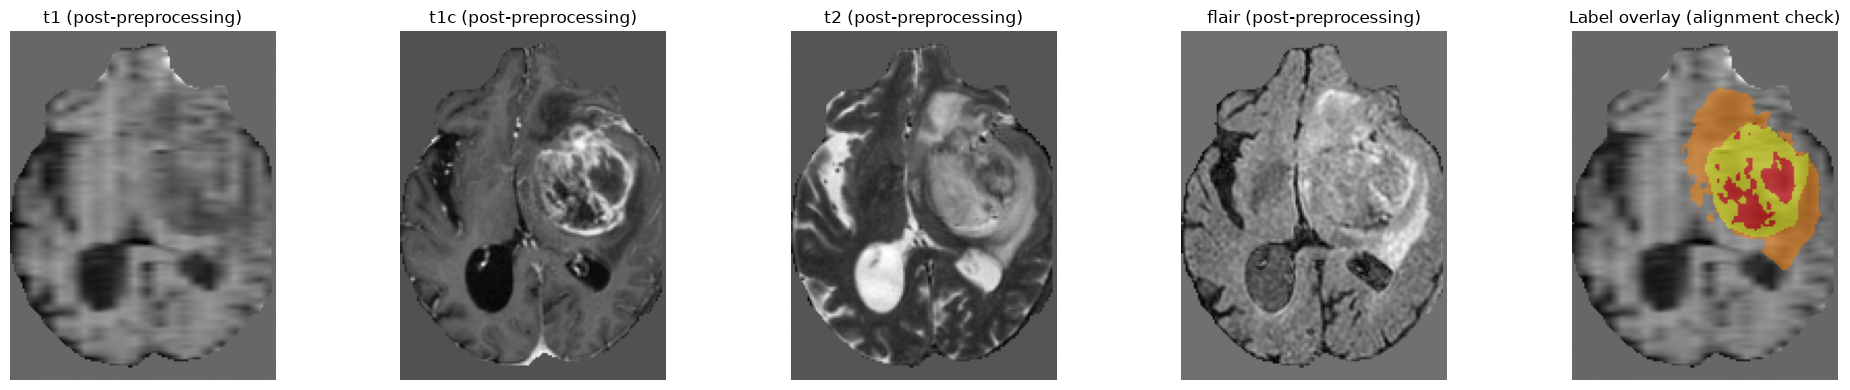

In [14]:
def visualize_processed_batch(batch, modality_names=MODALITY_KEYS):
    if batch is None:
        print("No batch available to visualize.")
        return

    image = batch["image"][0]  # (modalities, X, Y, Z)
    label = batch["seg"][0][0]  # (X, Y, Z), single channel label

    z_mid = image.shape[-1] // 2

    n_mod = image.shape[0]
    fig, axes = plt.subplots(1, n_mod + 1, figsize=(4 * (n_mod + 1), 4))

    for i in range(n_mod):
        name = modality_names[i] if i < len(modality_names) else f"modality_{i}"
        axes[i].imshow(image[i, :, :, z_mid].T, cmap="gray", origin="lower")
        axes[i].set_title(f"{name} (post-preprocessing)")
        axes[i].axis("off")

    axes[-1].imshow(image[0, :, :, z_mid].T, cmap="gray", origin="lower")
    seg_slice = label[:, :, z_mid]
    masked = np.ma.masked_where(seg_slice.numpy().T == 0, seg_slice.numpy().T)
    axes[-1].imshow(masked, cmap="autumn", alpha=0.5, origin="lower")
    axes[-1].set_title("Label overlay (alignment check)")
    axes[-1].axis("off")

    plt.tight_layout()
    plt.show()

visualize_processed_batch(sample_batch)


## Cell 13 — Model Definition (3D U-Net)

A MONAI 3D U-Net sized for CPU experimentation — fewer channels/levels than a full-scale
configuration, to keep forward/backward passes tractable without a GPU.


In [15]:
from monai.networks.nets import UNet
from monai.networks.layers import Norm

IN_CHANNELS = len(MODALITY_KEYS)   # T1, T1c, T2, FLAIR
OUT_CHANNELS = NUM_CLASSES         # background + 3 tumor sub-regions

def build_model(in_channels=IN_CHANNELS, out_channels=OUT_CHANNELS, device=DEVICE):
    '''Build a lightweight 3D U-Net suitable for CPU experimentation.'''
    model = UNet(
        spatial_dims=3,
        in_channels=in_channels,
        out_channels=out_channels,
        channels=(16, 32, 64, 128),
        strides=UNET_STRIDES,  # must match the strides used to size DivisiblePadd in Cell 6
        num_res_units=2,
        norm=Norm.BATCH,
    ).to(device)
    return model

model = build_model()

n_params = sum(p.numel() for p in model.parameters())
print("Model: MONAI 3D U-Net")
print("-" * 40)
print(f"Input channels:  {IN_CHANNELS} ({', '.join(MODALITY_KEYS)})")
print(f"Output channels: {OUT_CHANNELS} ({', '.join(RAW_LABELS.values())})")
print(f"Parameter count: {n_params:,}")
print(f"Device:          {DEVICE}")


Model: MONAI 3D U-Net
----------------------------------------
Input channels:  4 (t1, t1c, t2, flair)
Output channels: 4 (background, necrotic_core, edema, enhancing_tumor)
Parameter count: 1,192,573
Device:          cuda


## Cell 14 — Loss Function

`DiceCELoss` (Dice + cross-entropy) configured for multi-class segmentation with the raw integer
label map (not pre-one-hot-encoded) and softmax output.


In [16]:
from monai.losses import DiceCELoss

loss_function = DiceCELoss(
    to_onehot_y=True,   # convert integer label map to one-hot internally
    softmax=True,        # model outputs raw logits; softmax applied inside the loss
    include_background=True,
)

print("Loss function: DiceCELoss")
print("  to_onehot_y=True, softmax=True, include_background=True")


Loss function: DiceCELoss
  to_onehot_y=True, softmax=True, include_background=True


## Cell 15 — Metrics (Dice, IoU)

Validation metrics using MONAI's `DiceMetric` and `MeanIoU`, both configured to optionally exclude
the background class from the reported mean (background is trivially easy and would otherwise
inflate the score).


In [17]:
from monai.metrics import DiceMetric, MeanIoU
from monai.transforms import AsDiscrete

post_pred = AsDiscrete(argmax=True, to_onehot=NUM_CLASSES)
post_label = AsDiscrete(to_onehot=NUM_CLASSES)

dice_metric = DiceMetric(include_background=False, reduction="mean", get_not_nans=False)
iou_metric = MeanIoU(include_background=False, reduction="mean", get_not_nans=False)

print("Metrics configured: DiceMetric and MeanIoU (background excluded from the reported mean).")


Metrics configured: DiceMetric and MeanIoU (background excluded from the reported mean).


## Cell 16 — Forward-Pass Test

Run one real batch through the model **before** any training, purely to confirm shapes are
compatible end-to-end. This must succeed before the training loop is allowed to run.


In [18]:
def forward_pass_test(model, batch, device=DEVICE):
    if batch is None:
        print("No batch available — cannot run forward-pass test.")
        return False

    model.eval()
    image = batch["image"].to(device)
    target = batch["seg"].to(device)

    with torch.no_grad():
        output = model(image)

    print("Forward-Pass Test")
    print("-" * 40)
    print(f"Input shape:  {tuple(image.shape)}")
    print(f"Output shape: {tuple(output.shape)}")
    print(f"Target shape: {tuple(target.shape)}")

    ok = output.shape[0] == image.shape[0] and output.shape[1] == OUT_CHANNELS and output.shape[2:] == image.shape[2:]
    print(f"\nForward pass shape check: {'PASS' if ok else 'FAIL'}")
    return ok

forward_pass_ok = forward_pass_test(model, sample_batch)


Forward-Pass Test
----------------------------------------
Input shape:  (1, 4, 128, 168, 136)
Output shape: (1, 4, 128, 168, 136)
Target shape: (1, 1, 128, 168, 136)

Forward pass shape check: PASS


## Cell 17 — Training Configuration

Optimizer, learning rate, scheduler, and checkpoint directory. Epoch count is deliberately small —
this is for pipeline debugging, not a full training run. The training loop in the next cell does
**not** execute automatically; it must be run as an explicit, separate step.


In [19]:
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LEARNING_RATE = 1e-4
NUM_EPOCHS = 50         # generous ceiling — early stopping will likely halt sooner
EARLY_STOP_PATIENCE = 15  # stop if val_dice hasn't improved for this many epochs
WEIGHT_DECAY = 1e-5

optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
lr_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

print("Training Configuration")
print("-" * 40)
print(f"Optimizer:             Adam (lr={LEARNING_RATE}, weight_decay={WEIGHT_DECAY})")
print(f"Scheduler:             CosineAnnealingLR (T_max={NUM_EPOCHS})")
print(f"Max epochs:            {NUM_EPOCHS}")
print(f"Early stop patience:   {EARLY_STOP_PATIENCE} epochs without val_dice improvement")
print(f"Checkpoint dir:        {CHECKPOINT_DIR}")
print(f"Device:                {DEVICE}")

Training Configuration
----------------------------------------
Optimizer:             Adam (lr=0.0001, weight_decay=1e-05)
Scheduler:             CosineAnnealingLR (T_max=50)
Max epochs:            50
Early stop patience:   15 epochs without val_dice improvement
Checkpoint dir:        C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints
Device:                cuda


## Cell 18 — Training Loop

A short, explicit training run. Trains only on `train_loader`, validates only on `val_loader`
(never on `test_loader`), tracks the best validation Dice, and checkpoints the best model.

**This cell does not run unless you execute it.** Given `NUM_EPOCHS` is small, this is meant for
pipeline verification, not final model quality.


In [20]:
def run_training(model, train_loader, val_loader, loss_function, optimizer, scheduler,
                  num_epochs, device, checkpoint_dir, print_every=25, patience=15):
    import time
    history = {"train_loss": [], "val_loss": [], "val_dice": []}
    best_val_dice = -1.0
    epochs_without_improvement = 0
    best_ckpt_path = checkpoint_dir / "best_model.pth"

    for epoch in range(1, num_epochs + 1):
        model.train()
        epoch_train_loss = 0.0
        epoch_start = time.time()

        for batch_idx, batch in enumerate(train_loader, start=1):
            batch_start = time.time()

            image = batch["image"].to(device)
            target = batch["seg"].to(device)
            optimizer.zero_grad()
            output = model(image)
            loss = loss_function(output, target)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

            if batch_idx % print_every == 0 or batch_idx == len(train_loader):
                batch_time = time.time() - batch_start
                elapsed = time.time() - epoch_start
                remaining_batches = len(train_loader) - batch_idx
                est_remaining_min = (elapsed / batch_idx) * remaining_batches / 60
                print(f"  Epoch {epoch}/{num_epochs} — train batch {batch_idx}/{len(train_loader)} "
                      f"— loss={loss.item():.4f} — {batch_time:.1f}s/batch "
                      f"— ~{est_remaining_min:.0f} min left this epoch", flush=True)

        epoch_train_loss /= max(len(train_loader), 1)

        model.eval()
        epoch_val_loss = 0.0
        dice_metric.reset()
        with torch.no_grad():
            for batch_idx, batch in enumerate(val_loader, start=1):
                image = batch["image"].to(device)
                target = batch["seg"].to(device)
                output = model(image)
                val_loss = loss_function(output, target)
                epoch_val_loss += val_loss.item()

                pred_list = [post_pred(o) for o in torch.unbind(output, dim=0)]
                label_list = [post_label(t) for t in torch.unbind(target, dim=0)]
                dice_metric(y_pred=pred_list, y=label_list)

                if batch_idx % print_every == 0 or batch_idx == len(val_loader):
                    print(f"  Epoch {epoch}/{num_epochs} — val batch {batch_idx}/{len(val_loader)}", flush=True)

        epoch_val_loss /= max(len(val_loader), 1)
        epoch_val_dice = dice_metric.aggregate().item() if len(val_loader) > 0 else float("nan")
        scheduler.step()

        history["train_loss"].append(epoch_train_loss)
        history["val_loss"].append(epoch_val_loss)
        history["val_dice"].append(epoch_val_dice)

        epoch_time = time.time() - epoch_start
        print(f"Epoch {epoch}/{num_epochs} — "
              f"train_loss={epoch_train_loss:.4f}  val_loss={epoch_val_loss:.4f}  "
              f"val_dice={epoch_val_dice:.4f}  ({epoch_time/60:.1f} min)")

        if epoch_val_dice > best_val_dice:
            best_val_dice = epoch_val_dice
            epochs_without_improvement = 0
            torch.save(model.state_dict(), best_ckpt_path)
            print(f"  New best validation Dice ({best_val_dice:.4f}) — saved checkpoint to {best_ckpt_path}")
        else:
            epochs_without_improvement += 1
            print(f"  No improvement for {epochs_without_improvement}/{patience} epochs")

        if epochs_without_improvement >= patience:
            print(f"\nEarly stopping at epoch {epoch} — "
                  f"validation Dice has not improved in {patience} consecutive epochs.")
            break

    return history, best_val_dice, best_ckpt_path

RUN_TRAINING = True  # set True explicitly to actually run the loop below

if RUN_TRAINING:
    if not forward_pass_ok:
        print("Forward-pass test did not pass — fix the pipeline before training.")
    elif len(train_loader) == 0 or len(val_loader) == 0:
        print("Training or validation loader is empty — cannot train. Check your dataset/splits.")
    else:
        training_history, best_val_dice, best_ckpt_path = run_training(
            model, train_loader, val_loader, loss_function, optimizer, lr_scheduler,
            NUM_EPOCHS, DEVICE, CHECKPOINT_DIR, print_every=25, patience=EARLY_STOP_PATIENCE
        )
else:
    print("RUN_TRAINING is False — training loop skipped by design.")
    print("Set RUN_TRAINING = True and re-run this cell once all pipeline checks above pass.")
    training_history, best_val_dice, best_ckpt_path = None, None, CHECKPOINT_DIR / "best_model.pth"

  Epoch 1/50 — train batch 25/875 — loss=2.2744 — 0.2s/batch — ~36 min left this epoch
  Epoch 1/50 — train batch 50/875 — loss=2.1302 — 0.2s/batch — ~32 min left this epoch
  Epoch 1/50 — train batch 75/875 — loss=2.0468 — 0.1s/batch — ~31 min left this epoch
  Epoch 1/50 — train batch 100/875 — loss=1.9296 — 0.1s/batch — ~29 min left this epoch
  Epoch 1/50 — train batch 125/875 — loss=1.8293 — 0.2s/batch — ~28 min left this epoch
  Epoch 1/50 — train batch 150/875 — loss=1.6881 — 0.2s/batch — ~28 min left this epoch
  Epoch 1/50 — train batch 175/875 — loss=1.6111 — 0.2s/batch — ~27 min left this epoch
  Epoch 1/50 — train batch 200/875 — loss=1.5006 — 0.2s/batch — ~27 min left this epoch
  Epoch 1/50 — train batch 225/875 — loss=1.3738 — 0.2s/batch — ~26 min left this epoch
  Epoch 1/50 — train batch 250/875 — loss=1.2614 — 0.2s/batch — ~25 min left this epoch
  Epoch 1/50 — train batch 275/875 — loss=1.1490 — 0.2s/batch — ~24 min left this epoch
  Epoch 1/50 — train batch 300/875 

## Cell 19 — Training Curves

Plot training/validation loss and validation Dice across epochs, and save the figure to
`outputs/`. Skipped gracefully if training has not been run yet.


Saved training curves to: C:\Users\shshi\Downloads\Med_Twin\outputs\training_curves.png


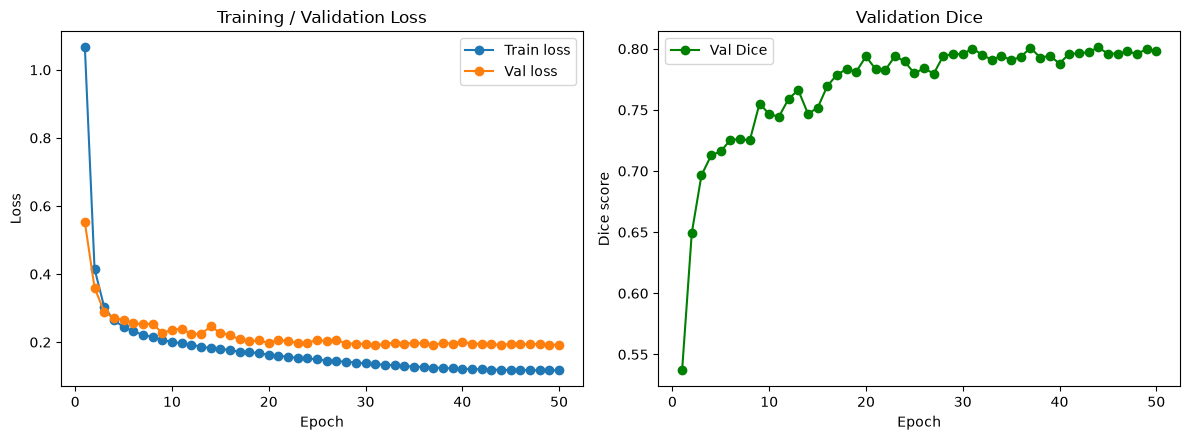

In [21]:
def plot_training_curves(history, output_dir):
    if not history or not history.get("train_loss"):
        print("No training history available yet — run the training loop first.")
        return

    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(epochs, history["train_loss"], label="Train loss", marker="o")
    axes[0].plot(epochs, history["val_loss"], label="Val loss", marker="o")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Training / Validation Loss")
    axes[0].legend()

    axes[1].plot(epochs, history["val_dice"], label="Val Dice", marker="o", color="green")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Dice score")
    axes[1].set_title("Validation Dice")
    axes[1].legend()

    plt.tight_layout()

    fig_path = output_dir / "training_curves.png"
    plt.savefig(fig_path, dpi=150)
    print(f"Saved training curves to: {fig_path}")
    plt.show()

plot_training_curves(training_history, OUTPUT_DIR)


## Cell 20 — Test Evaluation

Load the best checkpoint and evaluate **only** on the held-out test set (never used during
training or model selection). Reports mean Dice/IoU and per-class values.


In [22]:
def evaluate_on_test(model, checkpoint_path, test_loader, device, num_classes):
    if not checkpoint_path.exists():
        print(f"No checkpoint found at {checkpoint_path} — train the model first (Cell 18).")
        return None
    if len(test_loader) == 0:
        print("Test loader is empty — cannot evaluate. Check your dataset/splits.")
        return None

    model.load_state_dict(torch.load(checkpoint_path, map_location=device))
    model.to(device)
    model.eval()

    dice_metric.reset()
    iou_metric.reset()

    with torch.no_grad():
        for batch in test_loader:
            image = batch["image"].to(device)
            target = batch["seg"].to(device)

            output = model(image)
            pred_list = [post_pred(o) for o in torch.unbind(output, dim=0)]
            label_list = [post_label(t) for t in torch.unbind(target, dim=0)]

            dice_metric(y_pred=pred_list, y=label_list)
            iou_metric(y_pred=pred_list, y=label_list)

    mean_dice = dice_metric.aggregate().item()
    mean_iou = iou_metric.aggregate().item()

    print("Test Set Evaluation")
    print("-" * 40)
    print(f"Checkpoint: {checkpoint_path}")
    print(f"Mean Dice (excluding background): {mean_dice:.4f}")
    print(f"Mean IoU  (excluding background): {mean_iou:.4f}")
    print("\nNote: per-class breakdown requires `reduction=None` on the metrics; "
          "re-run with per-class reduction if a class-by-class table is needed.")

    return {"mean_dice": mean_dice, "mean_iou": mean_iou}

test_results = evaluate_on_test(model, best_ckpt_path, test_loader, DEVICE, NUM_CLASSES)


Test Set Evaluation
----------------------------------------
Checkpoint: C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth
Mean Dice (excluding background): 0.7822
Mean IoU  (excluding background): 0.6939

Note: per-class breakdown requires `reduction=None` on the metrics; re-run with per-class reduction if a class-by-class table is needed.


## Cell 21 — Qualitative Prediction on Unseen Test Patients

Visually compare MRI, ground truth, and predicted mask for a few held-out test patients.


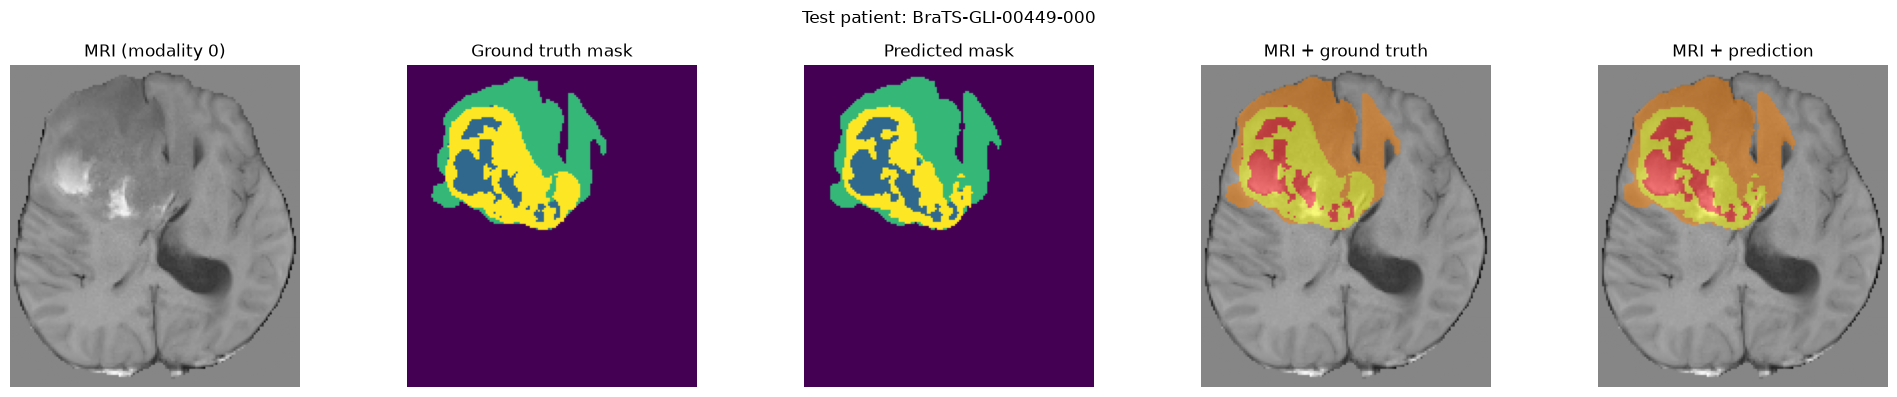

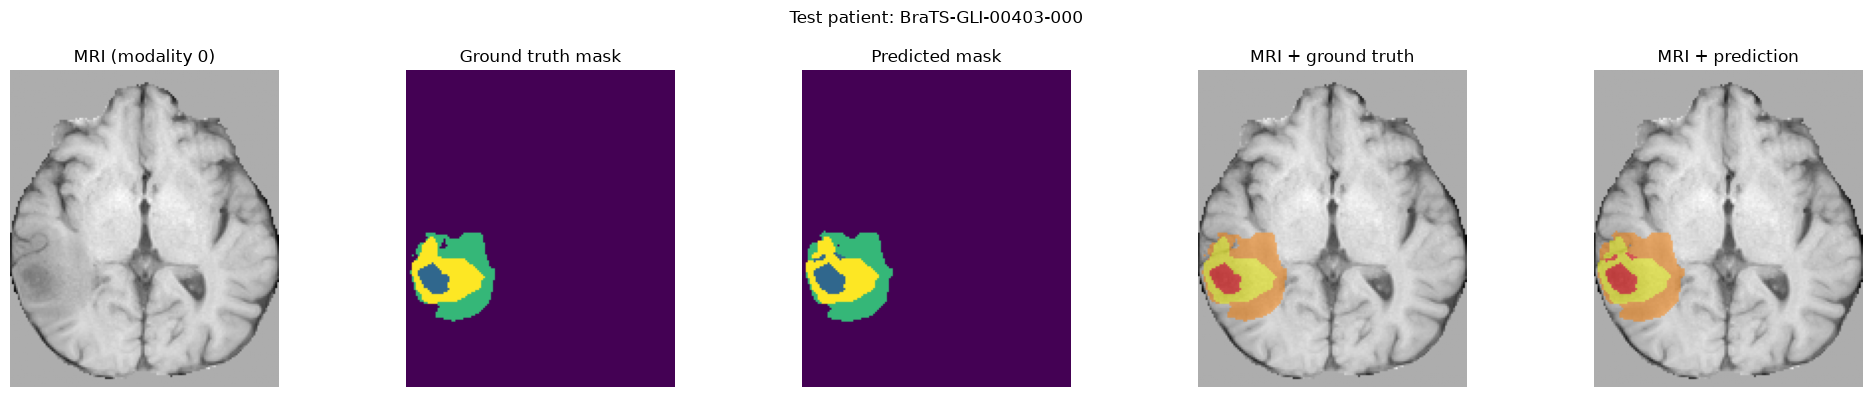

In [23]:
def visualize_qualitative_prediction(model, test_loader, device, n_examples=2):
    if not best_ckpt_path.exists():
        print("No trained checkpoint available yet — run training (Cell 18) first.")
        return
    if len(test_loader) == 0:
        print("Test loader is empty — nothing to visualize.")
        return

    model.eval()
    shown = 0
    with torch.no_grad():
        for batch in test_loader:
            if shown >= n_examples:
                break

            image = batch["image"].to(device)
            target = batch["seg"].to(device)
            output = model(image)
            pred = torch.argmax(output, dim=1, keepdim=True)

            img_np = image[0, 0].cpu().numpy()      # first modality channel for display
            gt_np = target[0, 0].cpu().numpy()
            pred_np = pred[0, 0].cpu().numpy()
            z_mid = img_np.shape[-1] // 2

            fig, axes = plt.subplots(1, 5, figsize=(20, 4))
            axes[0].imshow(img_np[:, :, z_mid].T, cmap="gray", origin="lower")
            axes[0].set_title("MRI (modality 0)")

            axes[1].imshow(gt_np[:, :, z_mid].T, cmap="viridis", origin="lower")
            axes[1].set_title("Ground truth mask")

            axes[2].imshow(pred_np[:, :, z_mid].T, cmap="viridis", origin="lower")
            axes[2].set_title("Predicted mask")

            axes[3].imshow(img_np[:, :, z_mid].T, cmap="gray", origin="lower")
            gt_masked = np.ma.masked_where(gt_np[:, :, z_mid].T == 0, gt_np[:, :, z_mid].T)
            axes[3].imshow(gt_masked, cmap="autumn", alpha=0.5, origin="lower")
            axes[3].set_title("MRI + ground truth")

            axes[4].imshow(img_np[:, :, z_mid].T, cmap="gray", origin="lower")
            pred_masked = np.ma.masked_where(pred_np[:, :, z_mid].T == 0, pred_np[:, :, z_mid].T)
            axes[4].imshow(pred_masked, cmap="autumn", alpha=0.5, origin="lower")
            axes[4].set_title("MRI + prediction")

            for ax in axes:
                ax.axis("off")

            patient_id = batch["patient_id"][0] if "patient_id" in batch else "unknown"
            fig.suptitle(f"Test patient: {patient_id}")
            plt.tight_layout()
            plt.show()

            shown += 1

visualize_qualitative_prediction(model, test_loader, DEVICE)


## Cell 22 — Save Model and Configuration

Save the trained weights alongside the model configuration, label mapping, preprocessing
configuration, and split information — everything needed to run inference on a new user's MRI
later, without retraining.


In [24]:
import json

def save_full_model_bundle(output_dir, checkpoint_path, model_config, label_mapping,
                            preprocessing_config, split_info):
    bundle_dir = output_dir / "model_bundle"
    bundle_dir.mkdir(parents=True, exist_ok=True)

    bundle = {
        "checkpoint_path": str(checkpoint_path),
        "model_config": model_config,
        "label_mapping": label_mapping,
        "preprocessing_config": preprocessing_config,
        "split_info": split_info,
    }

    bundle_path = bundle_dir / "model_bundle.json"
    with open(bundle_path, "w") as f:
        json.dump(bundle, f, indent=2, default=str)

    print(f"Saved model bundle metadata to: {bundle_path}")
    if checkpoint_path.exists():
        print(f"Model weights checkpoint: {checkpoint_path}")
    else:
        print(f"NOTE: checkpoint not found at {checkpoint_path} — train the model first (Cell 18).")

    return bundle_path

model_config = {
    "architecture": "MONAI 3D UNet",
    "spatial_dims": 3,
    "in_channels": IN_CHANNELS,
    "out_channels": OUT_CHANNELS,
    "channels": (16, 32, 64, 128),
    "strides": (2, 2, 2),
    "num_res_units": 2,
    "modality_order": MODALITY_KEYS,
}

preprocessing_config = {
    "target_orientation": TARGET_ORIENTATION,
    "target_spacing_mm": TARGET_SPACING,
    "normalization": "NormalizeIntensityd(nonzero=True, channel_wise=True)",
    "crop": "CropForegroundd(source_key=image)",
}

split_info = {
    "seed": SPLIT_SEED,
    "train_patients": train_df["patient_id"].tolist(),
    "val_patients": val_df["patient_id"].tolist(),
    "test_patients": test_df["patient_id"].tolist(),
}

bundle_path = save_full_model_bundle(
    OUTPUT_DIR, best_ckpt_path, model_config, RAW_LABELS, preprocessing_config, split_info
)


Saved model bundle metadata to: C:\Users\shshi\Downloads\Med_Twin\outputs\model_bundle\model_bundle.json
Model weights checkpoint: C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth


## Cell 23 — Final Training Readiness Report

A single summary of dataset, split, model, and (if training was run) results — plus the pipeline
readiness checklist from before training.


In [25]:
def print_readiness_report():
    print("=" * 60)
    print("PHASE 2 — TRAINING PIPELINE READINESS REPORT")
    print("=" * 60)

    print(f"\nDataset directory:     {DATASET_DIR}")
    print(f"Total patients found:  {len(patients_df)}")
    print(f"Training patients:     {len(train_df)}")
    print(f"Validation patients:   {len(val_df)}")
    print(f"Test patients:         {len(test_df)}")
    print(f"Input modalities:      {', '.join(MODALITY_KEYS)}")
    print(f"Target voxel spacing:  {TARGET_SPACING} mm")

    print(f"\nModel:                 MONAI 3D UNet ({sum(p.numel() for p in model.parameters()):,} params)")
    print(f"Loss:                  DiceCELoss")
    print(f"Optimizer:             Adam (lr={LEARNING_RATE})")

    if training_history and training_history.get("val_dice"):
        print(f"\nBest validation Dice:  {best_val_dice:.4f}")
    else:
        print("\nBest validation Dice:  N/A (training not run yet)")

    if test_results:
        print(f"Test Dice:             {test_results['mean_dice']:.4f}")
        print(f"Test IoU:              {test_results['mean_iou']:.4f}")
    else:
        print("Test Dice:             N/A (test evaluation not run yet)")
        print("Test IoU:              N/A (test evaluation not run yet)")

    print(f"\nCheckpoint location:   {best_ckpt_path}")

    print("\n" + "-" * 60)
    print("Pre-training pipeline checks")
    print("-" * 60)
    checks = {
        "Dataset discovery found patients": len(patients_df) > 0,
        "At least one complete patient": bool(patients_df["complete_case"].any()) if len(patients_df) else False,
        "Compatibility check ran": len(compatibility_results) > 0,
        "Patient split created (no overlap)": len(train_df) > 0 and len(val_df) > 0 and len(test_df) > 0,
        "DataLoaders created": len(train_loader) >= 0,
        "One batch loaded successfully": sample_batch is not None,
        "Forward pass succeeded": forward_pass_ok,
    }
    for name, passed in checks.items():
        print(f"  [{'PASS' if passed else 'FAIL'}] {name}")

    all_passed = all(checks.values())
    print()
    if all_passed:
        print("PHASE 2 TRAINING PIPELINE READY")
    else:
        print("Pipeline is NOT fully ready — resolve the FAILed checks above before training at scale.")

    print(
        "\nReminder: this is a research prototype. No claim of clinical validation is made or implied "
        "by these results."
    )

print_readiness_report()


PHASE 2 — TRAINING PIPELINE READINESS REPORT

Dataset directory:     C:\Users\shshi\Downloads\Med_Twin\Dataset\ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData
Total patients found:  1251
Training patients:     875
Validation patients:   188
Test patients:         188
Input modalities:      t1, t1c, t2, flair
Target voxel spacing:  (1.0, 1.0, 1.0) mm

Model:                 MONAI 3D UNet (1,192,573 params)
Loss:                  DiceCELoss
Optimizer:             Adam (lr=0.0001)

Best validation Dice:  0.8011
Test Dice:             0.7822
Test IoU:              0.6939

Checkpoint location:   C:\Users\shshi\Downloads\Med_Twin\outputs\checkpoints\best_model.pth

------------------------------------------------------------
Pre-training pipeline checks
------------------------------------------------------------
  [PASS] Dataset discovery found patients
  [PASS] At least one complete patient
  [PASS] Compatibility check ran
  [PASS] Patient split created (no overlap)
  [PASS] DataLoaders c